# Telco Churn: Segmentation and Risk Analysis

**Purpose:** Define transparent, rule-based customer segments and identify which segment combinations carry the highest churn risk. This notebook uses only hand-crafted segments — no machine learning — so every boundary is explainable and auditable.

**Why rule-based segmentation first?**
Before deploying a model, it is essential to understand the data's natural structure. Rule-based segments are transparent (any stakeholder can verify membership), stable across time, and directly mappable to business actions.

**Causation caveat:** Segment churn rates are descriptive. High risk in a segment means that segment *historically had* more churners — it does not guarantee future churn or explain why.

## 1. Load data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 110

FILE_NAME = "telco_clean.csv"
project_root = next(
    folder
    for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "data" / "clean" / FILE_NAME).exists()
)

clean_path = project_root / "data" / "clean" / FILE_NAME
images_dir = project_root / "images"
images_dir.mkdir(exist_ok=True)

df = pd.read_csv(clean_path)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
df["CLV_Proxy"] = df["MonthlyCharges"] * df["tenure"]

addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]
df["AddonCount"] = (df[addon_cols] == "Yes").sum(axis=1)

print("Loaded from:", clean_path.resolve())
print("Shape:", df.shape)
print("Overall churn rate:", f"{df['ChurnFlag'].mean():.1%}")

Loaded from: D:\telco-churn-analytics\data\clean\telco_clean.csv
Shape: (7043, 25)
Overall churn rate: 26.5%


## 2. Tenure segments

We divide tenure into three strategically meaningful groups:
- **New** (0–12 months): customers still in the "trial" phase; highest churn risk
- **Growing** (13–36 months): customers who have committed past the first year
- **Loyal** (37–72 months): long-tenured customers with established relationships

These boundaries are business choices, not statistical optima. They are documented here so they can be revisited.

In [2]:
df["TenureSegment"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 36, 72],
    labels=["New (0-12 mo)", "Growing (13-36 mo)", "Loyal (37-72 mo)"],
    include_lowest=True,
)

tenure_seg = (
    df.groupby("TenureSegment", observed=True)["ChurnFlag"]
    .agg(customers="count", churned="sum")
    .assign(
        churn_rate=lambda x: x["churned"] / x["customers"],
        pct_of_base=lambda x: x["customers"] / len(df),
    )
)
tenure_seg["churn_rate_pct"] = tenure_seg["churn_rate"].map("{:.1%}".format)
tenure_seg["pct_of_base_pct"] = tenure_seg["pct_of_base"].map("{:.1%}".format)
print("=== Tenure Segments ===")
print(tenure_seg[["customers", "churned", "churn_rate_pct", "pct_of_base_pct"]].to_string())

=== Tenure Segments ===
                    customers  churned churn_rate_pct pct_of_base_pct
TenureSegment                                                        
New (0-12 mo)            2186     1037          47.4%           31.0%
Growing (13-36 mo)       1856      474          25.5%           26.4%
Loyal (37-72 mo)         3001      358          11.9%           42.6%


## 3. Charge segments

We bin MonthlyCharges into three groups based on the data's distribution:
- **Low** ($0–$35): mostly phone-only or no-internet customers
- **Mid** ($35–$65): bundled plans
- **High** ($65–$120): full Fiber Optic bundles with add-ons

These boundaries are based on the observed distribution and round to natural breaks in the data.

In [3]:
print("MonthlyCharges distribution:")
print(df["MonthlyCharges"].describe().round(2).to_string())
print()
print("Percentiles:")
print(df["MonthlyCharges"].quantile([0.25, 0.5, 0.75]).round(2).to_string())

df["ChargeSegment"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 65, 120],
    labels=["Low ($0-35)", "Mid ($35-65)", "High ($65-120)"],
    include_lowest=True,
)

charge_seg = (
    df.groupby("ChargeSegment", observed=True)["ChurnFlag"]
    .agg(customers="count", churned="sum")
    .assign(
        churn_rate=lambda x: x["churned"] / x["customers"],
        pct_of_base=lambda x: x["customers"] / len(df),
    )
)
charge_seg["churn_rate_pct"] = charge_seg["churn_rate"].map("{:.1%}".format)
print()
print("=== Charge Segments ===")
print(charge_seg[["customers", "churned", "churn_rate_pct"]].to_string())

MonthlyCharges distribution:
count    7043.00
mean       64.76
std        30.09
min        18.25
25%        35.50
50%        70.35
75%        89.85
max       118.75

Percentiles:
0.25    35.50
0.50    70.35
0.75    89.85

=== Charge Segments ===
                customers  churned churn_rate_pct
ChargeSegment                                    
Low ($0-35)          1735      189          10.9%
Mid ($35-65)         1409      326          23.1%
High ($65-120)       3899     1354          34.7%


## 4. Composite risk segments: contract + tenure + charge

Combining the three dimensions above gives a 3-way segment. We focus on the cells with the highest churn rates *and* meaningful customer counts. We define a **High Risk** flag using business-driven rules:

```
High Risk = Month-to-month contract
            AND tenure <= 12 months
            AND MonthlyCharges >= $65
```

This combination represents a new, expensive, uncommitted customer — the profile most associated with churn in this data. The rule is transparent and can be changed.

In [4]:
# --- 3-way cross-tab: contract x tenure segment x churn rate ---
three_way = (
    df.groupby(["Contract", "TenureSegment"], observed=True)["ChurnFlag"]
    .agg(customers="count", churned="sum")
    .assign(churn_rate=lambda x: x["churned"] / x["customers"])
    .sort_values("churn_rate", ascending=False)
    .head(10)
)
three_way["churn_rate_pct"] = three_way["churn_rate"].map("{:.1%}".format)

print("=== Top 10 Contract x Tenure Segment Combinations by Churn Rate ===")
print(three_way[["customers", "churned", "churn_rate_pct"]].to_string())

=== Top 10 Contract x Tenure Segment Combinations by Churn Rate ===
                                   customers  churned churn_rate_pct
Contract       TenureSegment                                        
Month-to-month New (0-12 mo)            1994     1024          51.4%
               Growing (13-36 mo)       1223      436          35.7%
               Loyal (37-72 mo)          658      195          29.6%
One year       Loyal (37-72 mo)          902      117          13.0%
               New (0-12 mo)             124       13          10.5%
               Growing (13-36 mo)        447       36           8.1%
Two year       Loyal (37-72 mo)         1441       46           3.2%
               Growing (13-36 mo)        186        2           1.1%
               New (0-12 mo)              68        0           0.0%


In [5]:
# --- Apply High-Risk flag ---
df["HighRisk"] = (
    (df["Contract"] == "Month-to-month")
    & (df["tenure"] <= 12)
    & (df["MonthlyCharges"] >= 65)
)

hr_count = df["HighRisk"].sum()
hr_churn_rate = df[df["HighRisk"]]["ChurnFlag"].mean()
hr_monthly_rev = df[df["HighRisk"]]["MonthlyCharges"].sum()
overall_rate = df["ChurnFlag"].mean()

print("=== High-Risk Segment ===")
print(f"Definition: Month-to-month + tenure <= 12 mo + MonthlyCharges >= $65")
print(f"Customers in segment:          {hr_count:,} ({hr_count/len(df):.1%} of base)")
print(f"Churn rate in segment:         {hr_churn_rate:.1%}")
print(f"Overall base churn rate:       {overall_rate:.1%}")
print(f"Relative risk vs base:         {hr_churn_rate/overall_rate:.1f}x")
print(f"Monthly revenue in segment:    ${hr_monthly_rev:,.0f}")
print()
print("Interpretation: This segment has a churn rate significantly above the overall")
print("base rate. It is not the only high-risk group, but it is a targeted starting")
print("point for retention interventions.")

=== High-Risk Segment ===
Definition: Month-to-month + tenure <= 12 mo + MonthlyCharges >= $65
Customers in segment:          976 (13.9% of base)
Churn rate in segment:         67.7%
Overall base churn rate:       26.5%
Relative risk vs base:         2.6x
Monthly revenue in segment:    $79,388

Interpretation: This segment has a churn rate significantly above the overall
base rate. It is not the only high-risk group, but it is a targeted starting
point for retention interventions.


## 5. Visualising the segment landscape

A bubble chart where each bubble is a contract x tenure segment, sized by customer count, and colored by churn rate. This gives a simultaneous view of size and risk.

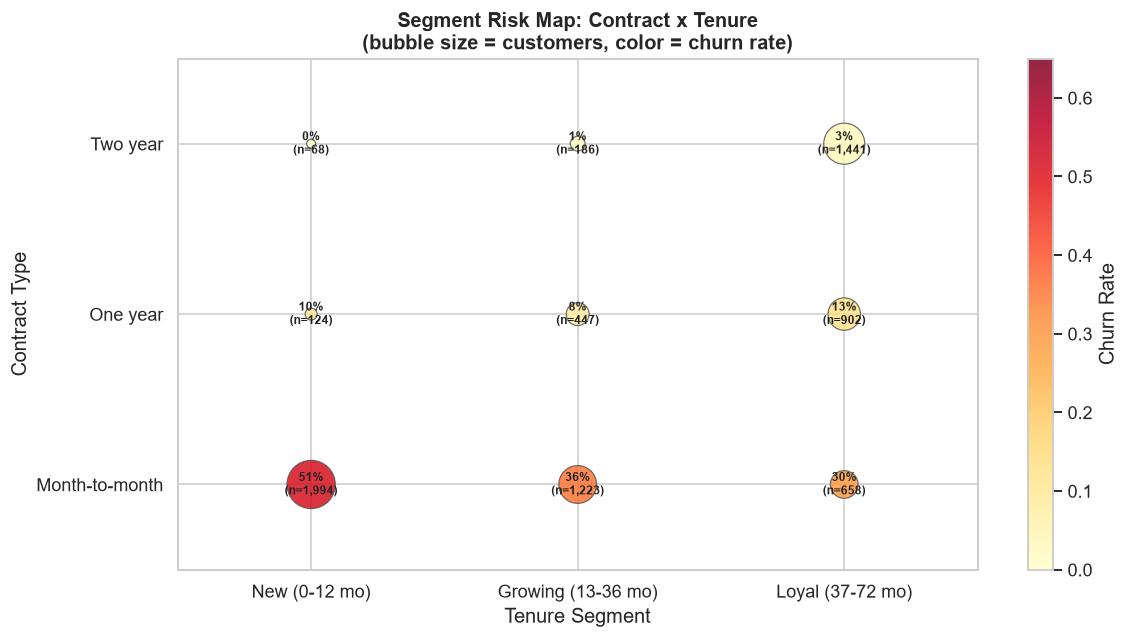

Saved: images/04_01_segment_risk_map.png


In [6]:
seg_pivot = (
    df.groupby(["Contract", "TenureSegment"], observed=True)["ChurnFlag"]
    .agg(customers="count", churned="sum")
    .assign(churn_rate=lambda x: x["churned"] / x["customers"])
    .reset_index()
)

contract_map = {"Month-to-month": 0, "One year": 1, "Two year": 2}
tenure_map = {"New (0-12 mo)": 0, "Growing (13-36 mo)": 1, "Loyal (37-72 mo)": 2}

seg_pivot["x"] = seg_pivot["TenureSegment"].map(tenure_map)
seg_pivot["y"] = seg_pivot["Contract"].map(contract_map)

fig, ax = plt.subplots(figsize=(11, 6))

scatter = ax.scatter(
    seg_pivot["x"],
    seg_pivot["y"],
    s=seg_pivot["customers"] / 2,
    c=seg_pivot["churn_rate"],
    cmap="YlOrRd",
    vmin=0,
    vmax=0.65,
    edgecolors="#555",
    linewidths=0.8,
    alpha=0.85,
    zorder=3,
)

for _, row in seg_pivot.iterrows():
    ax.annotate(
        f"{row['churn_rate']:.0%}\n(n={int(row['customers']):,})",
        (row["x"], row["y"]),
        ha="center", va="center",
        fontsize=8, fontweight="bold", color="#222",
    )

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["New (0-12 mo)", "Growing (13-36 mo)", "Loyal (37-72 mo)"])
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["Month-to-month", "One year", "Two year"])
ax.set_xlabel("Tenure Segment")
ax.set_ylabel("Contract Type")
ax.set_title(
    "Segment Risk Map: Contract x Tenure\n"
    "(bubble size = customers, color = churn rate)",
    fontweight="bold",
)
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(-0.5, 2.5)
plt.colorbar(scatter, ax=ax, label="Churn Rate")
plt.tight_layout()
plt.savefig(images_dir / "04_01_segment_risk_map.png", bbox_inches="tight")
plt.show()
print("Saved: images/04_01_segment_risk_map.png")

## 6. High-risk customer profile

Within the high-risk segment, we look at the distribution of internet service type, payment method, and add-on count to characterise what a typical high-risk customer looks like.

In [7]:
hr_df = df[df["HighRisk"]].copy()

print("=== High-Risk Segment Profile (Month-to-month + tenure<=12 + charges>=$65) ===")
print(f"Total customers in segment: {len(hr_df):,}")
print(f"Churned: {hr_df['ChurnFlag'].sum():,} ({hr_df['ChurnFlag'].mean():.1%})")
print()
for col in ["InternetService", "PaymentMethod", "SeniorCitizenLabel", "AddonCount"]:
    print(f"--- {col} ---")
    if col == "AddonCount":
        print(hr_df[col].value_counts().sort_index().to_string())
    else:
        print(hr_df[col].value_counts().to_string())
    print()

=== High-Risk Segment Profile (Month-to-month + tenure<=12 + charges>=$65) ===
Total customers in segment: 976
Churned: 661 (67.7%)

--- InternetService ---
InternetService
Fiber optic    916
DSL             60

--- PaymentMethod ---
PaymentMethod
Electronic check             657
Mailed check                 135
Bank transfer (automatic)    100
Credit card (automatic)       84

--- SeniorCitizenLabel ---
SeniorCitizenLabel
No     745
Yes    231

--- AddonCount ---
AddonCount
0    282
1    291
2    200
3    138
4     54
5     10
6      1



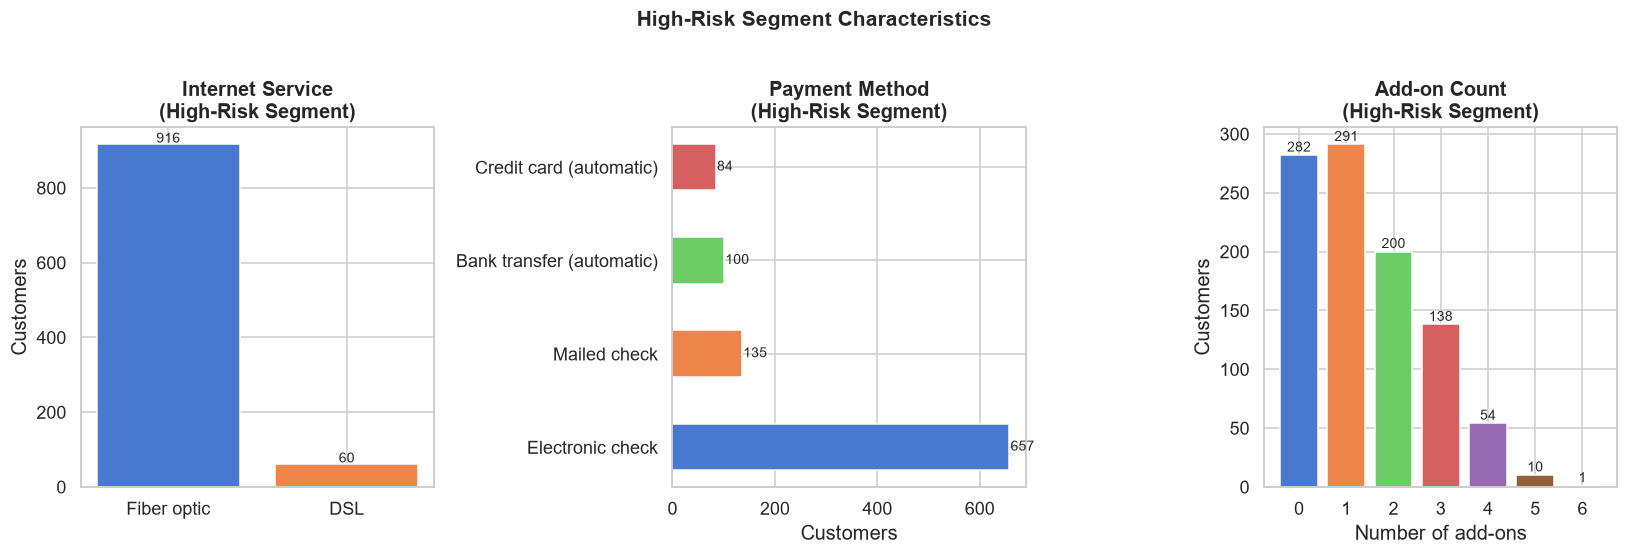

Saved: images/04_02_high_risk_profile.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

palette2 = sns.color_palette("muted")

# Internet service breakdown in high-risk segment
inet_counts = hr_df["InternetService"].value_counts()
axes[0].bar(inet_counts.index, inet_counts.values, color=palette2[:len(inet_counts)], edgecolor="white")
axes[0].set_title("Internet Service\n(High-Risk Segment)", fontweight="bold")
axes[0].set_ylabel("Customers")
for i, v in enumerate(inet_counts.values):
    axes[0].text(i, v + 5, str(v), ha="center", fontsize=9)

# Payment method breakdown
pay_counts = hr_df["PaymentMethod"].value_counts()
axes[1].barh(pay_counts.index, pay_counts.values,
             color=palette2[:len(pay_counts)], edgecolor="white", height=0.5)
axes[1].set_title("Payment Method\n(High-Risk Segment)", fontweight="bold")
axes[1].set_xlabel("Customers")
for i, v in enumerate(pay_counts.values):
    axes[1].text(v + 3, i, str(v), va="center", fontsize=9)

# Add-on count distribution
addon_counts = hr_df["AddonCount"].value_counts().sort_index()
axes[2].bar(addon_counts.index.astype(str), addon_counts.values,
            color=palette2[:len(addon_counts)], edgecolor="white")
axes[2].set_title("Add-on Count\n(High-Risk Segment)", fontweight="bold")
axes[2].set_xlabel("Number of add-ons")
axes[2].set_ylabel("Customers")
for i, v in enumerate(addon_counts.values):
    axes[2].text(i, v + 3, str(v), ha="center", fontsize=9)

fig.suptitle("High-Risk Segment Characteristics", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(images_dir / "04_02_high_risk_profile.png", bbox_inches="tight")
plt.show()
print("Saved: images/04_02_high_risk_profile.png")

## 7. Top 20 highest-churn combinations

An exhaustive multi-dimension cross-tab helps surface combinations that may not be obvious from pairwise analysis. We require at least 50 customers in a cell to avoid reporting statistically noisy rates.

In [9]:
combo = (
    df.groupby(["Contract", "InternetService", "PaymentMethod"], observed=True)["ChurnFlag"]
    .agg(customers="count", churned="sum")
    .assign(churn_rate=lambda x: x["churned"] / x["customers"])
    .query("customers >= 50")
    .sort_values("churn_rate", ascending=False)
    .head(20)
)
combo["churn_rate_pct"] = combo["churn_rate"].map("{:.1%}".format)

print("=== Top 20 Churn Rate Combinations (min 50 customers) ===")
print(combo[["customers", "churned", "churn_rate_pct"]].to_string())

=== Top 20 Churn Rate Combinations (min 50 customers) ===
                                                          customers  churned churn_rate_pct
Contract       InternetService PaymentMethod                                               
Month-to-month Fiber optic     Electronic check                1307      789          60.4%
                               Mailed check                     201      102          50.7%
                               Bank transfer (automatic)        327      149          45.6%
                               Credit card (automatic)          293      122          41.6%
               DSL             Electronic check                 474      192          40.5%
                               Mailed check                     367      113          30.8%
                               Credit card (automatic)          185       50          27.0%
One year       Fiber optic     Electronic check                 196       51          26.0%
Month-to-month No     

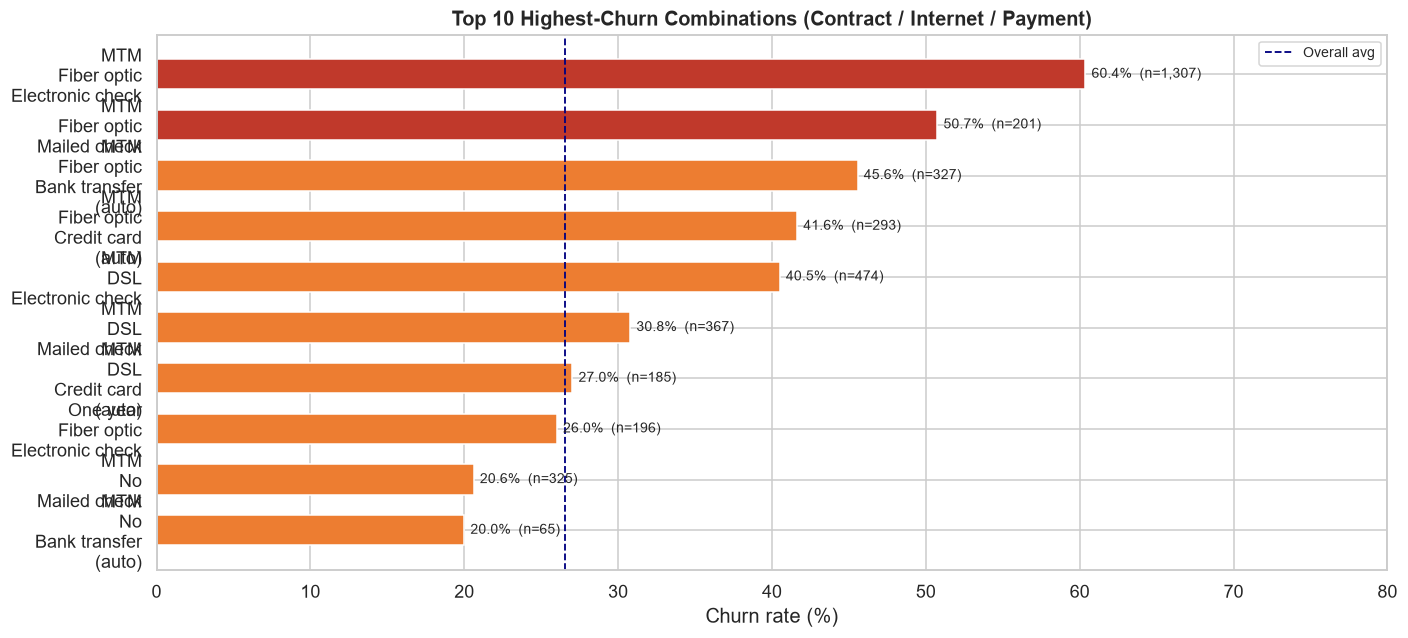

Saved: images/04_03_top_churn_combinations.png


In [10]:
# Visualise the top 10 combinations
top10 = combo.head(10).reset_index()
top10["label"] = (
    top10["Contract"].str.replace("Month-to-month", "MTM")
    + "\n" + top10["InternetService"]
    + "\n" + top10["PaymentMethod"].str.replace(" (automatic)", "\n(auto)", regex=False)
)

fig, ax = plt.subplots(figsize=(13, 6))
bar_colors = ["#c0392b" if r > 0.5 else "#ed7d31" for r in top10["churn_rate"]]
bars = ax.barh(top10["label"], top10["churn_rate"] * 100,
               color=bar_colors, edgecolor="white", height=0.6)
for bar, val, cnt in zip(bars, top10["churn_rate"], top10["customers"]):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.1%}  (n={cnt:,})",
        va="center", fontsize=9,
    )
ax.axvline(df["ChurnFlag"].mean() * 100, color="navy", linestyle="--",
           linewidth=1.2, label="Overall avg")
ax.set_title("Top 10 Highest-Churn Combinations (Contract / Internet / Payment)",
             fontweight="bold")
ax.set_xlabel("Churn rate (%)")
ax.set_xlim(0, 80)
ax.invert_yaxis()
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(images_dir / "04_03_top_churn_combinations.png", bbox_inches="tight")
plt.show()
print("Saved: images/04_03_top_churn_combinations.png")

## 8. Segmentation summary

A consolidated view of all defined segments and their churn metrics.

In [11]:
overall_rate = df["ChurnFlag"].mean()

hr_count = df["HighRisk"].sum()
hr_rate = df[df["HighRisk"]]["ChurnFlag"].mean()
hr_monthly = df[df["HighRisk"]]["MonthlyCharges"].sum()
hr_churned_monthly = df[(df["HighRisk"]) & (df["Churn"]=="Yes")]["MonthlyCharges"].sum()

print("============================================================")
print("  SEGMENTATION SUMMARY — Telco Churn")
print("============================================================")
print(f"  Overall churn rate:                   {overall_rate:.1%}")
print()
print("  Tenure Segments")
for idx, row in tenure_seg[["customers", "churn_rate_pct"]].iterrows():
    print(f"    {str(idx):<25} n={row['customers']:>5,}  rate={row['churn_rate_pct']}")
print()
print("  Charge Segments")
for idx, row in charge_seg[["customers", "churn_rate_pct"]].iterrows():
    print(f"    {str(idx):<25} n={row['customers']:>5,}  rate={row['churn_rate_pct']}")
print()
print("  High-Risk Rule-Based Segment")
print(f"    Definition: MTM contract + tenure<=12 mo + charges>=$65")
print(f"    Customers:  {hr_count:,} ({hr_count/len(df):.1%} of base)")
print(f"    Churn rate: {hr_rate:.1%}  (vs {overall_rate:.1%} overall)")
print(f"    Monthly revenue in segment:  ${hr_monthly:,.0f}")
print(f"    Monthly revenue from churned: ${hr_churned_monthly:,.0f}")
print("============================================================")
print()
print("Reminder: These segments describe historical patterns. They do not")
print("predict individual customer behaviour or explain why customers left.")

  SEGMENTATION SUMMARY — Telco Churn
  Overall churn rate:                   26.5%

  Tenure Segments
    New (0-12 mo)             n=2,186  rate=47.4%
    Growing (13-36 mo)        n=1,856  rate=25.5%
    Loyal (37-72 mo)          n=3,001  rate=11.9%

  Charge Segments
    Low ($0-35)               n=1,735  rate=10.9%
    Mid ($35-65)              n=1,409  rate=23.1%
    High ($65-120)            n=3,899  rate=34.7%

  High-Risk Rule-Based Segment
    Definition: MTM contract + tenure<=12 mo + charges>=$65
    Customers:  976 (13.9% of base)
    Churn rate: 67.7%  (vs 26.5% overall)
    Monthly revenue in segment:  $79,388
    Monthly revenue from churned: $54,442

Reminder: These segments describe historical patterns. They do not
predict individual customer behaviour or explain why customers left.
